# COVID-19 Global Statistics:Exploratory and Inferential Analysis

**Dataset:** `covid19_global_statistics_2026_with_imf_gdp.csv`

**Objective:** To examine the distribution of COVID-19 burden and its association with population and economic indicators using descriptive statistics, visualizations, correlation analysis, and simple linear regression.

# A. Data loading, structure, and preparation

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_PATH = "covid19_global_statistics_2026_with_imf_gdp.csv"
df_raw = pd.read_csv(DATA_PATH)

print("Dataset dimensions:", df_raw.shape)
display(df_raw.head())

Dataset dimensions: (184, 9)


,continent,country,population,cases_per_million,total_cases,deaths_per_million,total_deaths,GDP ( USD billions),GDP Per Capita(USD)
0,Africa,Niger,26083660,381,9931,12,312,26.110,864.478
1,Asia,China,1448471400,347,503302,4,5272,"20,650.754","14,730.309"
2,Africa,Liberia,5305117,1525,8090,56,295,5.594,955.666
3,Oceania,Nauru,10903,494635,5393,92,1,0.183,"14,958.977"
4,Africa,Comoros,907419,10038,9109,177,161,1.770,"1,904.282"



## Data types, structure, and missing values

In [6]:
print("Data types:")
display(df_raw.dtypes.rename("Data type").to_frame())
print("Dataset information:")
df_raw.info()
missing = pd.DataFrame({
    "Missing count": df_raw.isna().sum(),
    "Missing (%)": df_raw.isna().mean().mul(100)
})
display(missing)
print("Duplicate rows:", df_raw.duplicated().sum())
print("Duplicate country names:", df_raw["country"].duplicated().sum())

Data types:


,Data type
continent,str
country,str
population,int64
cases_per_million,int64
total_cases,int64
deaths_per_million,int64
total_deaths,int64
GDP ( USD billions),float64
GDP Per Capita(USD),float64


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   continent            184 non-null    str    
 1   country              184 non-null    str    
 2   population           184 non-null    int64  
 3   cases_per_million    184 non-null    int64  
 4   total_cases          184 non-null    int64  
 5   deaths_per_million   184 non-null    int64  
 6   total_deaths         184 non-null    int64  
 7   GDP ( USD billions)  184 non-null    float64
 8   GDP Per Capita(USD)  184 non-null    float64
dtypes: float64(2), int64(5), str(2)
memory usage: 15.7 KB


,Missing count,Missing (%)
continent,0,0.000
country,0,0.000
population,0,0.000
cases_per_million,0,0.000
total_cases,0,0.000
deaths_per_million,0,0.000
total_deaths,0,0.000
GDP ( USD billions),0,0.000
GDP Per Capita(USD),0,0.000


Duplicate rows: 0
Duplicate country names: 0



## Data cleaning and variable definitions
The country and continent fields are categorical identifiers; the remaining fields are numeric. The cleaning step standardizes column labels, trims text fields, converts numeric columns safely, and checks for impossible negative values.

In [7]:
df = df_raw.copy()
df.columns = (df.columns.str.strip()
              .str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True)
              .str.strip("_"))
df["country"] = df["country"].astype("string").str.strip()
df["continent"] = df["continent"].astype("string").str.strip()

numeric_cols = [
    "population", "cases_per_million", "total_cases",
    "deaths_per_million", "total_deaths",
    "gdp_usd_billions", "gdp_per_capita_usd"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Cleaned columns:", df.columns.tolist())
print("Rows before cleaning:", len(df))
print("Rows with missing country/continent:", df[["country", "continent"]].isna().any(axis=1).sum())
print("Negative values by numeric variable:")
display((df[numeric_cols] < 0).sum().rename("Negative count").to_frame())

# Retain records with a country identifier
df = df.dropna(subset=["country"]).copy()
print("Rows after basic cleaning:", len(df))

Cleaned columns: ['continent', 'country', 'population', 'cases_per_million', 'total_cases', 'deaths_per_million', 'total_deaths', 'gdp_usd_billions', 'gdp_per_capita_usd']
Rows before cleaning: 184
Rows with missing country/continent: 0
Negative values by numeric variable:


,Negative count
population,0
cases_per_million,0
total_cases,0
deaths_per_million,0
total_deaths,0
gdp_usd_billions,0
gdp_per_capita_usd,0


Rows after basic cleaning: 184



## Statistical summary of numerical variables

In [8]:
display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
population,184.000,"40,830,702.168","153,150,656.871","10,903.000","1,832,623.500","8,727,237.000","29,506,638.750","1,448,471,400.000"
cases_per_million,184.000,"178,202.891","197,194.721",347.000,"12,820.500","100,561.000","284,247.250","771,655.000"
total_cases,184.000,"3,570,773.467","10,883,346.968","2,943.000","43,973.750","346,717.000","1,920,548.000","111,820,082.000"
deaths_per_million,184.000,"1,303.527","1,389.989",3.000,132.750,775.500,"2,160.250","6,595.000"
total_deaths,184.000,"37,295.620","121,415.944",1.000,415.250,"3,618.500","19,127.500","1,219,487.000"
gdp_usd_billions,184.000,656.423,"2,878.396",0.061,15.943,51.587,334.639,"31,821.293"
gdp_per_capita_usd,184.000,"22,403.249","32,239.241",368.831,"2,954.806","8,700.210","29,996.033","246,738.259"


## Distribution and density plots

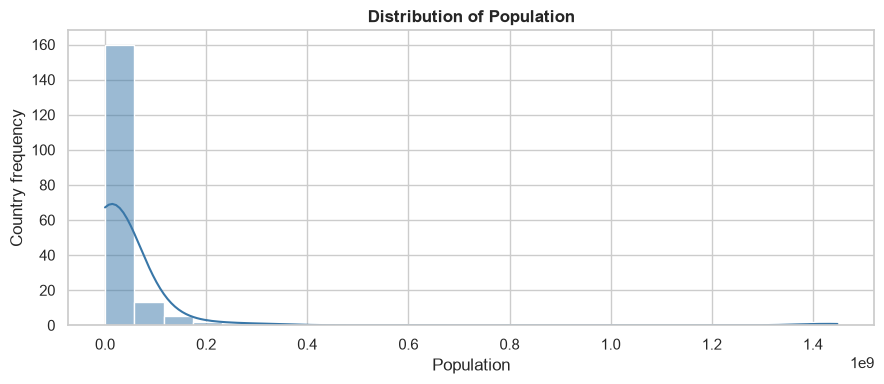

population: skewness = 8.285; kurtosis (excess) = 73.102


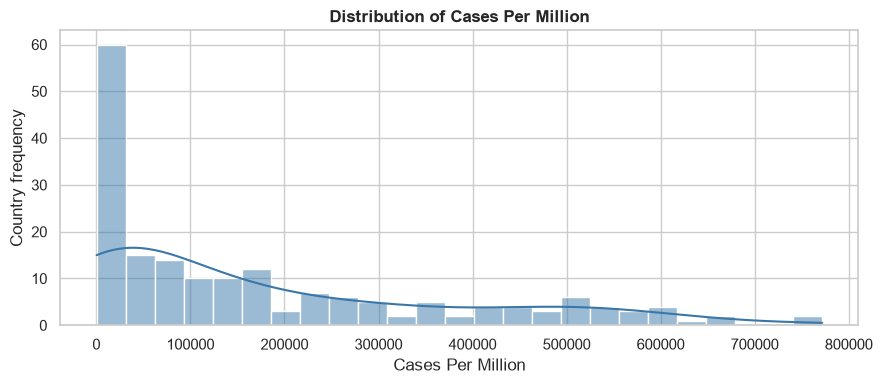

cases_per_million: skewness = 1.095; kurtosis (excess) = 0.123


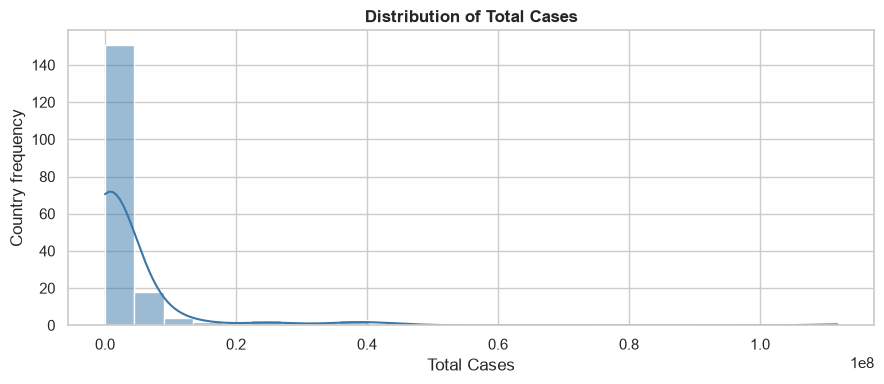

total_cases: skewness = 6.580; kurtosis (excess) = 55.999


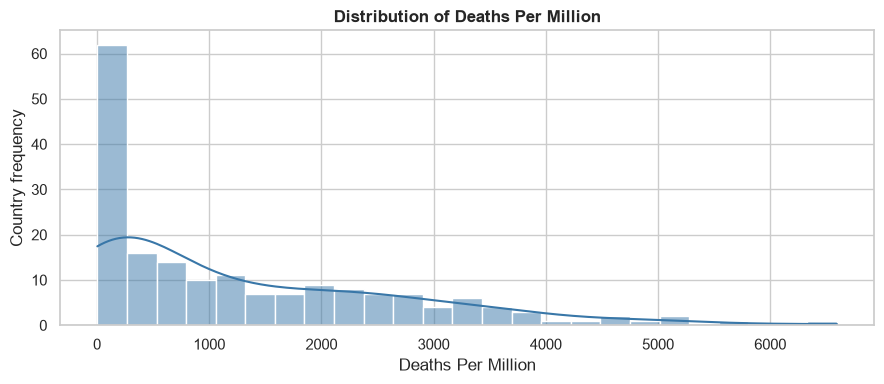

deaths_per_million: skewness = 1.193; kurtosis (excess) = 0.946


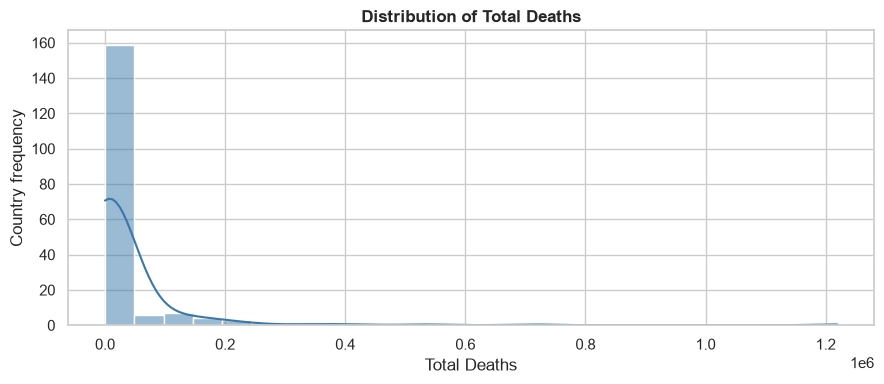

total_deaths: skewness = 6.732; kurtosis (excess) = 55.437


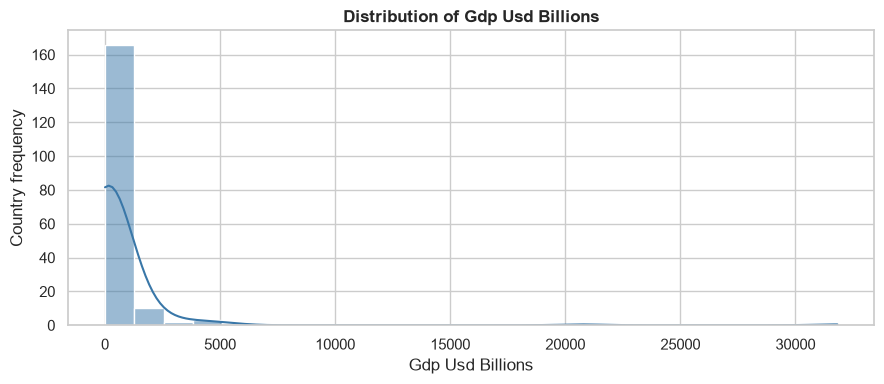

gdp_usd_billions: skewness = 8.930; kurtosis (excess) = 87.794


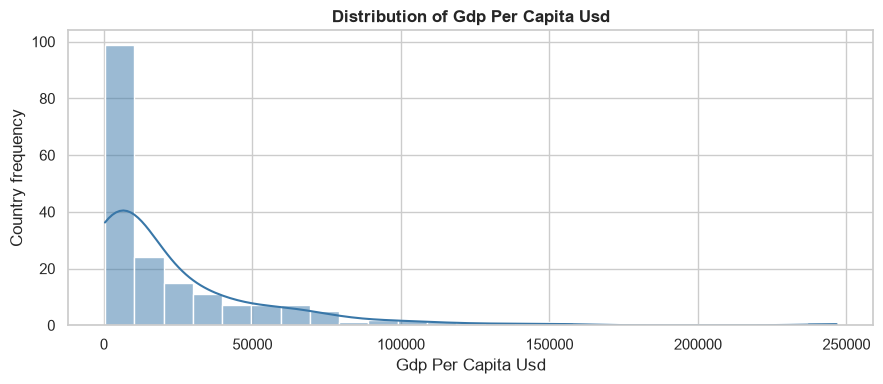

gdp_per_capita_usd: skewness = 3.096; kurtosis (excess) = 14.288


In [9]:
for col in numeric_cols:
    values = df[col].dropna()
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(values, bins=25, kde=True, ax=ax, color="#3977A8")
    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Country frequency")
    plt.tight_layout()
    plt.show()
    print(f"{col}: skewness = {values.skew():.3f}; kurtosis (excess) = {values.kurtosis():.3f}")


### Interpretation of Distribution Plots

The distributions show substantial positive skewness and heavy tails across most variables. GDP (skewness = 8.930; kurtosis = 87.794) and population (8.285; 73.102) have the highest values, indicating large differences between countries and extreme observations. Total deaths (6.732; 55.437) and total cases (6.580; 55.999) also exhibit long right tails, suggesting that a few countries account for disproportionately high totals. GDP per capita (3.096; 14.288) is also positively skewed. Deaths per million (1.193; 0.946) has comparatively lower skewness and kurtosis, indicating a less extreme distribution. Overall, most variables depart considerably from normality.


## B. Descriptive visualizations across countries
The requested country comparisons are shown as ranked horizontal bar charts. Countries are ranked by the variable being displayed so that the largest observations remain visible. The GDP variables use their supplied units: GDP is in USD billions and GDP per capita is in USD.

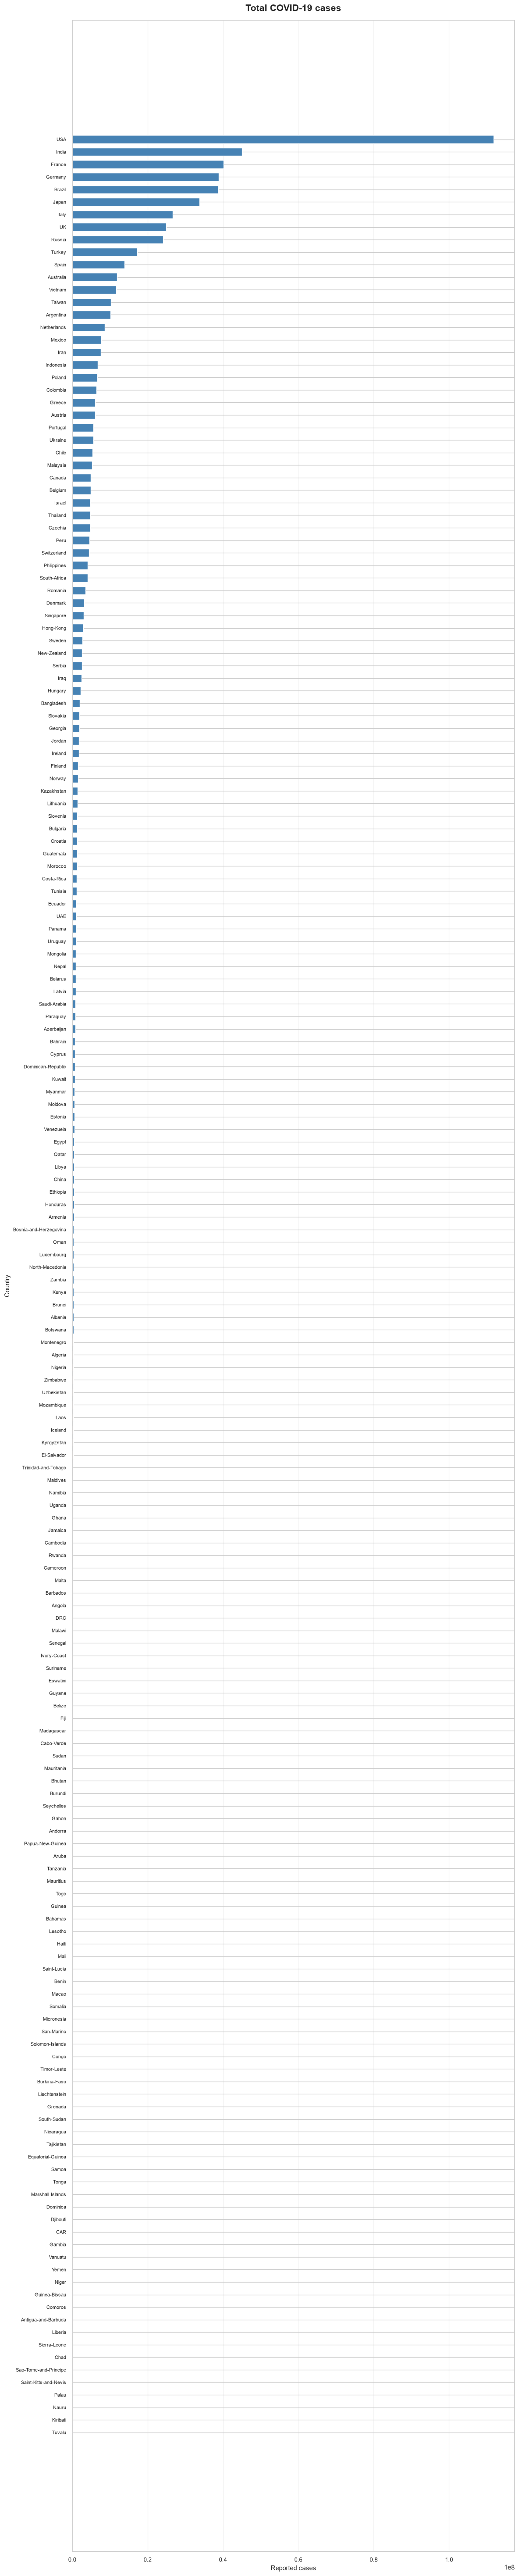

Highest five countries for total_cases:


,country,total_cases
0,USA,111820082
1,India,45035393
2,France,40138560
3,Germany,38828995
4,Brazil,38743918


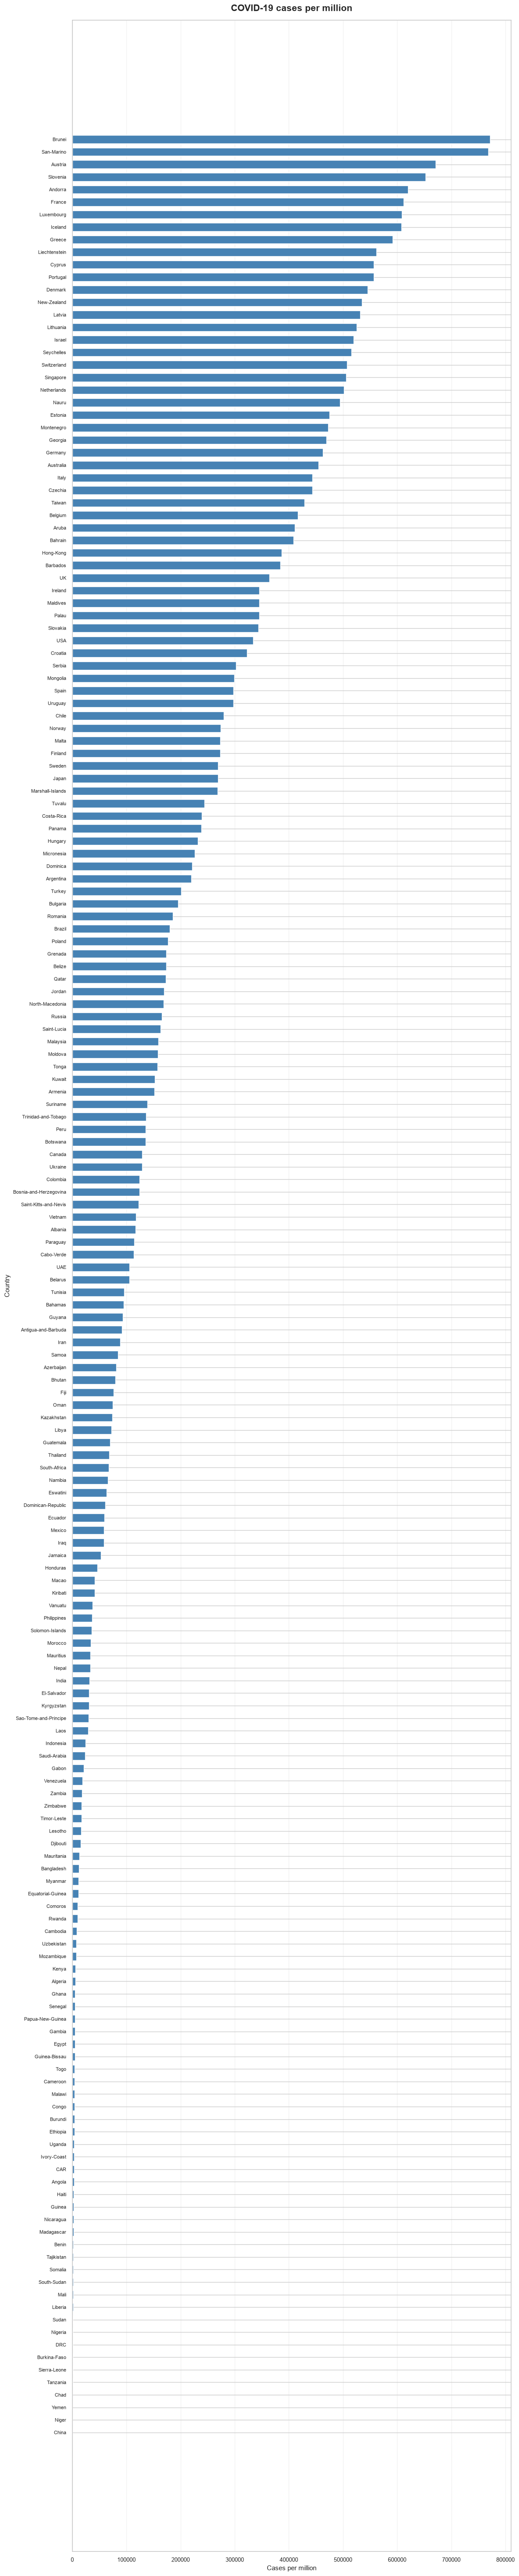

Highest five countries for cases_per_million:


,country,cases_per_million
0,Brunei,771655
1,San-Marino,768226
2,Austria,670727
3,Slovenia,652803
4,Andorra,619844


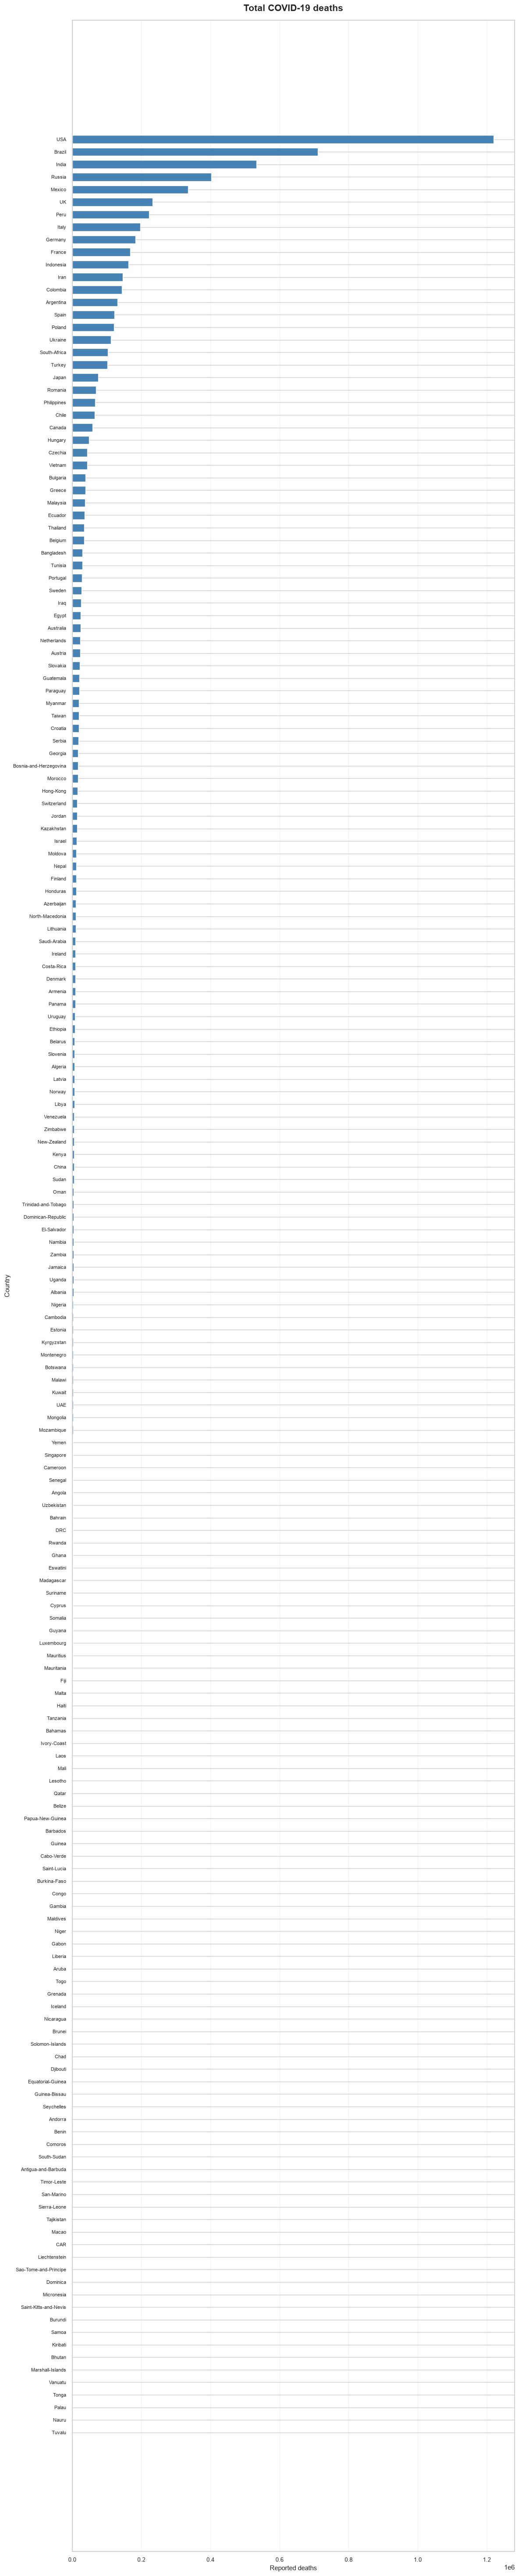

Highest five countries for total_deaths:


,country,total_deaths
0,USA,1219487
1,Brazil,711380
2,India,533570
3,Russia,402756
4,Mexico,334958


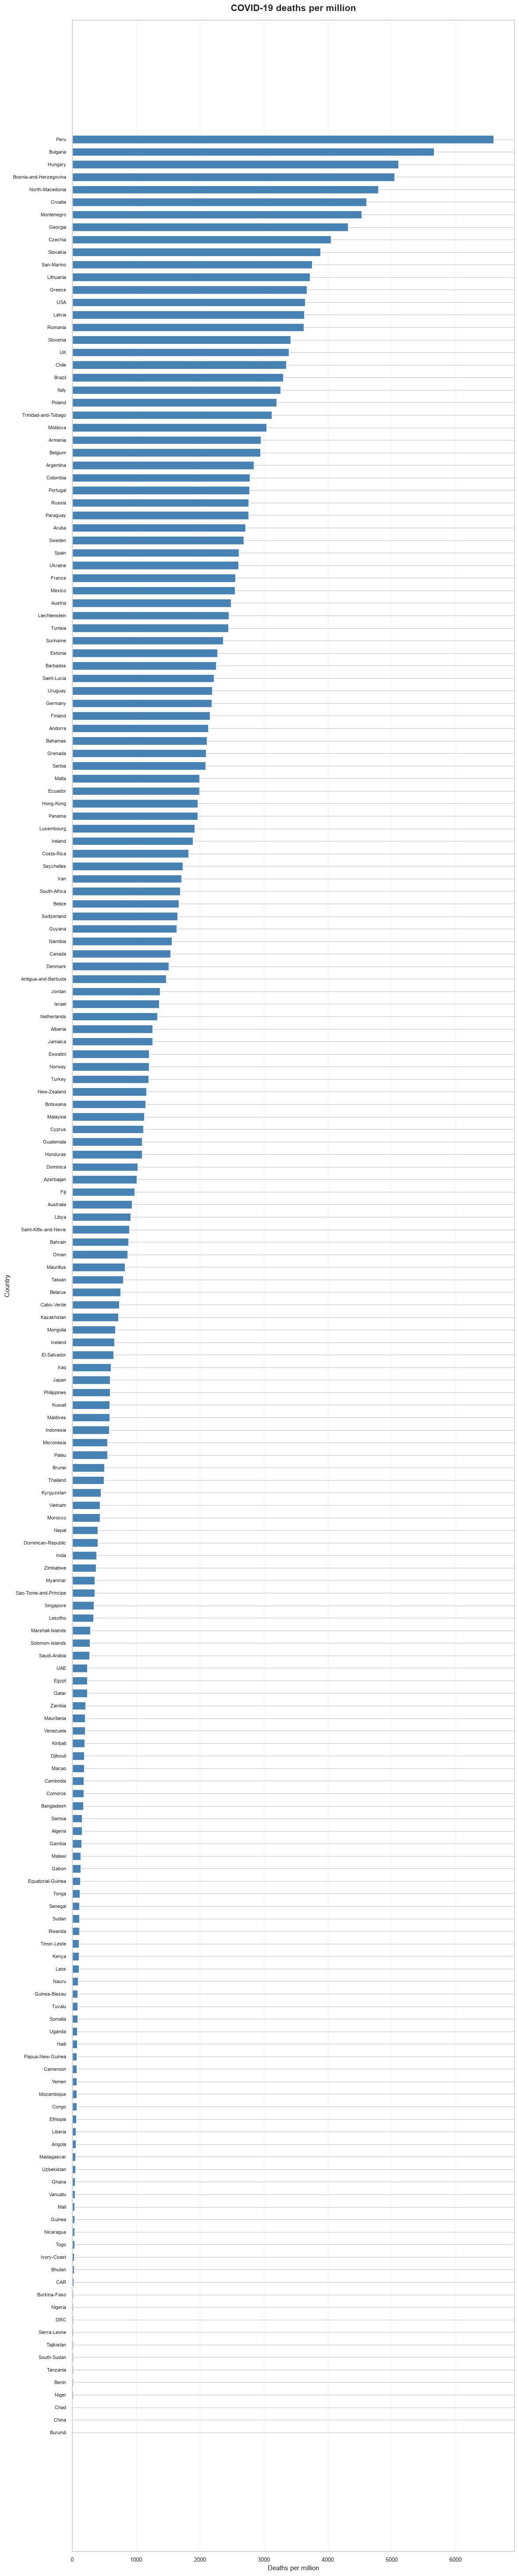

Highest five countries for deaths_per_million:


,country,deaths_per_million
0,Peru,6595
1,Bulgaria,5661
2,Hungary,5106
3,Bosnia-and-Herzegovina,5044
4,North-Macedonia,4793


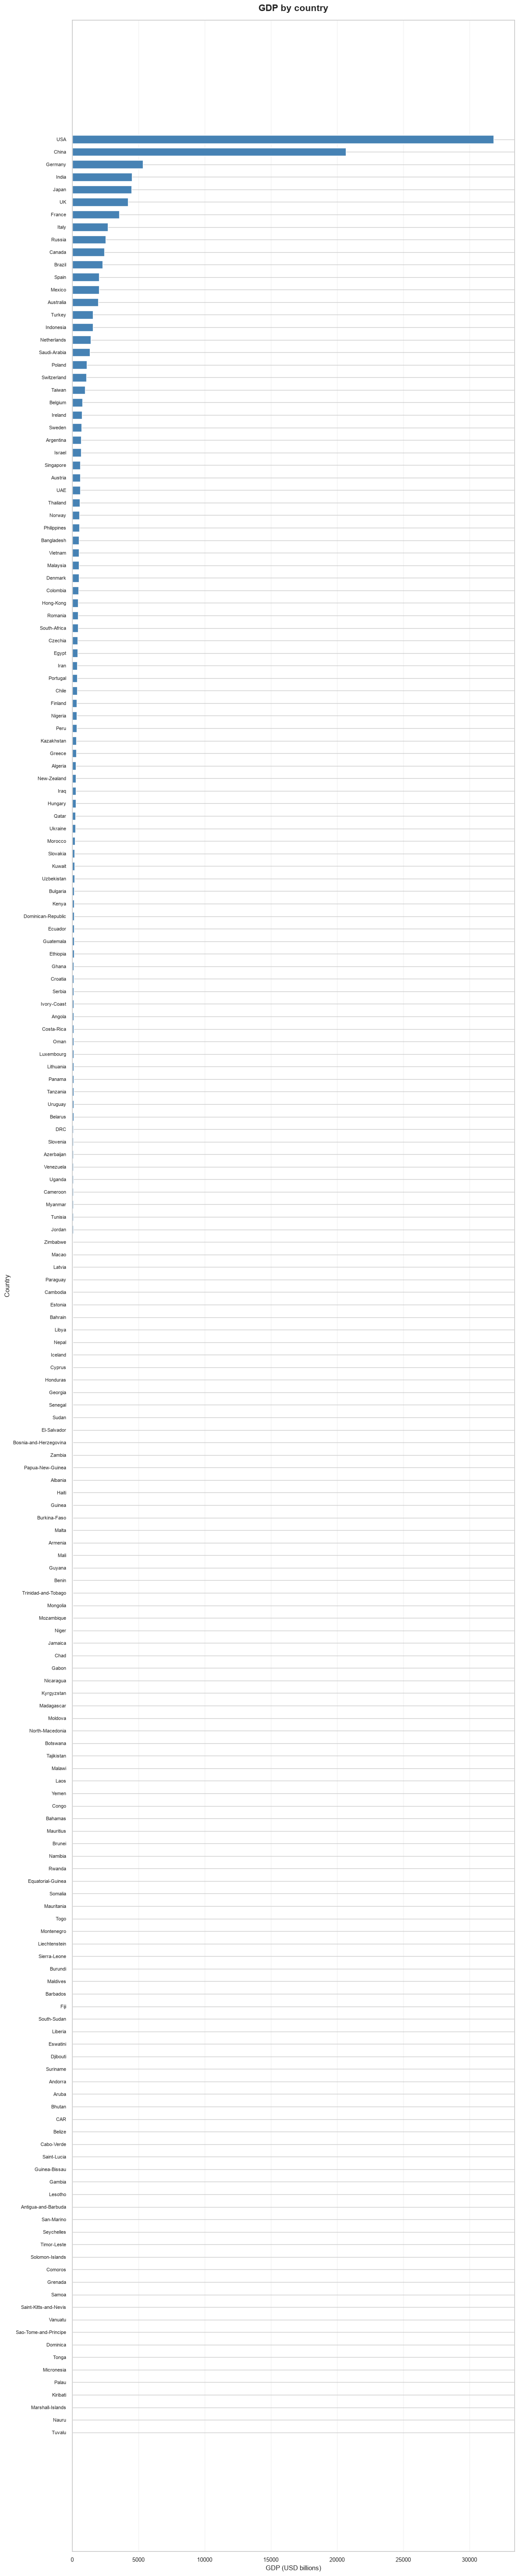

Highest five countries for gdp_usd_billions:


,country,gdp_usd_billions
0,USA,"31,821.293"
1,China,"20,650.754"
2,Germany,"5,328.184"
3,India,"4,505.629"
4,Japan,"4,463.634"


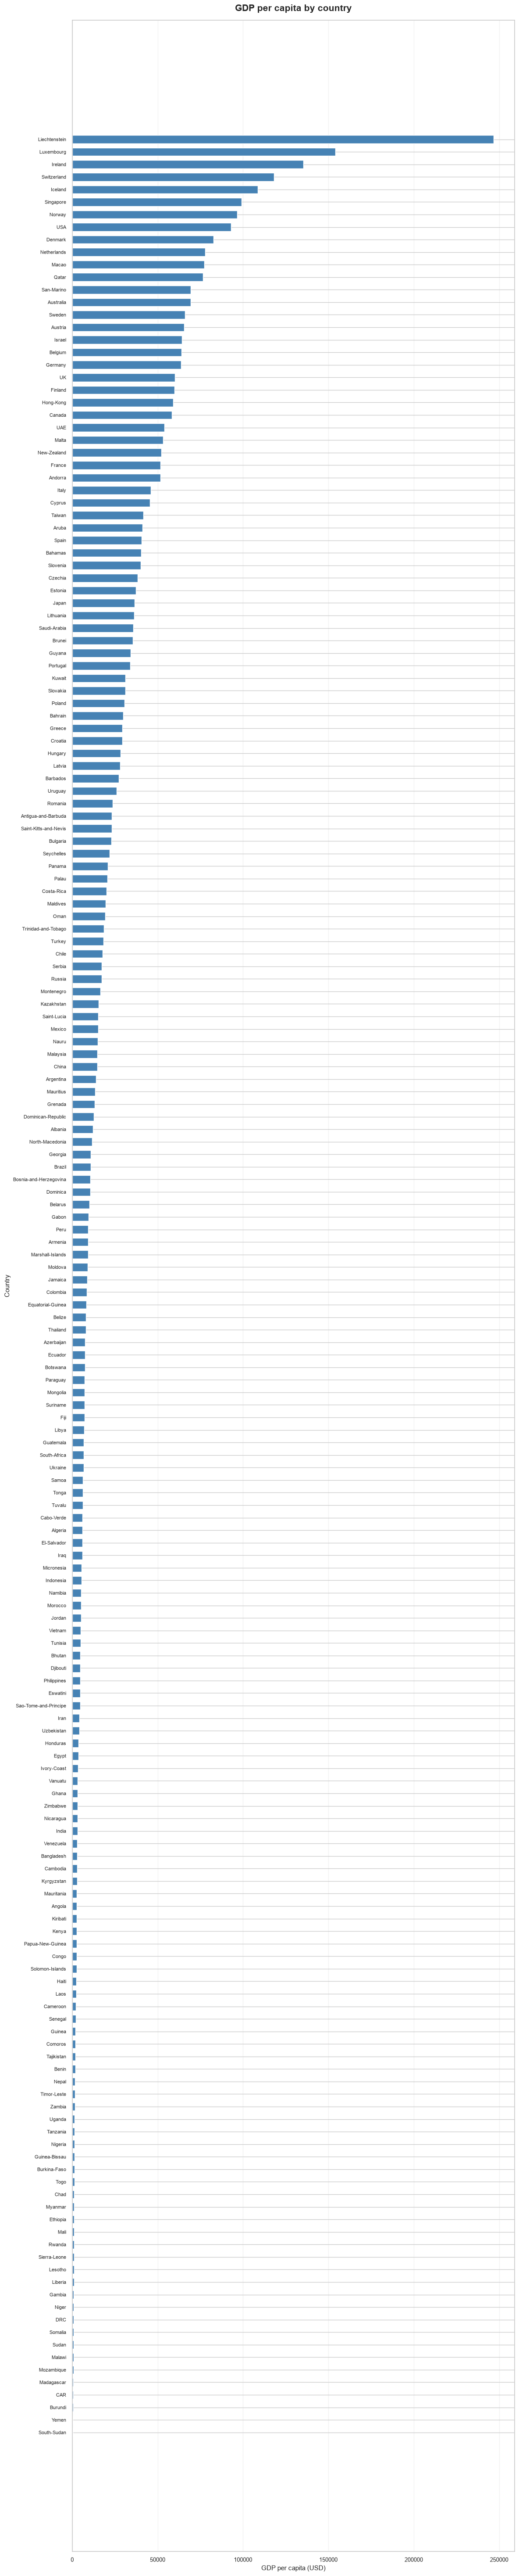

Highest five countries for gdp_per_capita_usd:


,country,gdp_per_capita_usd
0,Liechtenstein,"246,738.259"
1,Luxembourg,"154,115.478"
2,Ireland,"135,247.398"
3,Switzerland,"118,173.258"
4,Iceland,"108,591.227"


In [10]:
plot_specs = [
    ("total_cases", "Total COVID-19 cases", "Reported cases"),
    ("cases_per_million", "COVID-19 cases per million", "Cases per million"),
    ("total_deaths", "Total COVID-19 deaths", "Reported deaths"),
    ("deaths_per_million", "COVID-19 deaths per million", "Deaths per million"),
    ("gdp_usd_billions", "GDP by country", "GDP (USD billions)"),
    ("gdp_per_capita_usd", "GDP per capita by country", "GDP per capita (USD)")
]

for col, title, xlabel in plot_specs:
    plot_data = df[["country", col]].dropna().sort_values(
        col, ascending=False
    )

    fig, ax = plt.subplots(
        figsize=(12, max(12, len(plot_data) * 0.32))
    )

    ax.barh(
        plot_data["country"],
        plot_data[col],
        height=0.65,
        color="steelblue"
    )

    ax.invert_yaxis()
    ax.set_title(title, fontsize=15, pad=15)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel("Country", fontsize=11)

    ax.tick_params(axis="y", labelsize=8, pad=4)
    ax.tick_params(axis="x", labelsize=9)

    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()
    top = plot_data.head(5)
    print(f"Highest five countries for {col}:")
    display(top.reset_index(drop=True))


### Observations on Country-Level Comparisons

The country-level comparisons reveal considerable differences in COVID-19 burden and economic size. The United States recorded the highest total cases (111,820,082) and total deaths (1,219,487), followed by India and Brazil among the countries with the largest reported totals. This partly reflects the influence of population size on absolute case and death counts.

However, the population-adjusted rankings show a different pattern. Brunei recorded the highest cases per million (771,655), followed by San Marino and Austria, while Peru had the highest deaths per million (6,595), followed by Bulgaria and Hungary. This demonstrates that countries with the highest total cases or deaths do not necessarily have the highest rates relative to their populations.

For the economic indicators, the United States had the highest GDP (USD 31,821.293 billion), followed by China, Germany and India. In contrast, Liechtenstein recorded the highest GDP per capita (USD 246,738.259), followed by Luxembourg and Ireland. This highlights the difference between the overall size of an economy and its average economic output per person.

The rankings show that population size, COVID-19 burden and economic performance vary considerably across countries. Total cases and deaths are more informative about absolute burden, whereas per-million measures provide a more meaningful basis for comparing countries of different population sizes. Similarly, GDP measures overall economic size, while GDP per capita captures differences in economic output per person. These comparisons are descriptive and do not establish a causal relationship between economic performance and COVID-19 outcomes. Differences in testing, reporting practices, population characteristics and healthcare systems may also contribute to the observed patterns.


## Continent-level comparison and global country maps

,countries,population,total_cases,total_deaths,mean_cases_per_million,mean_deaths_per_million,mean_gdp_per_capita
continent,,,,,,,
Europe,42,747158123,253194055,2101272,"390,432.190","2,886.833","53,137.115"
Asia,42,4310821782,177744126,1442576,"167,269.024",728.429,"21,216.991"
North-America,22,585381535,130158862,1684321,"147,130.182","1,620.591","21,392.588"
South-America,11,425384079,68888777,1344505,"151,085.000","2,728.091","13,259.290"
Oceania,14,42863776,14724561,32041,"214,640.429",392.286,"14,911.649"
Africa,53,1401239904,12311937,257679,"27,587.094",318.000,"3,284.399"


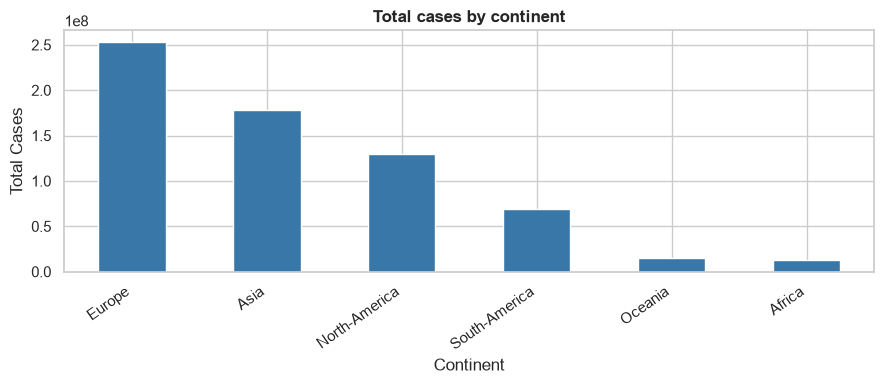

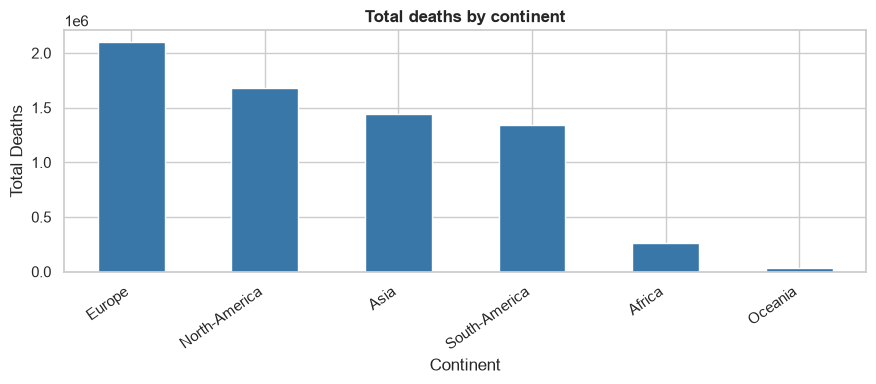

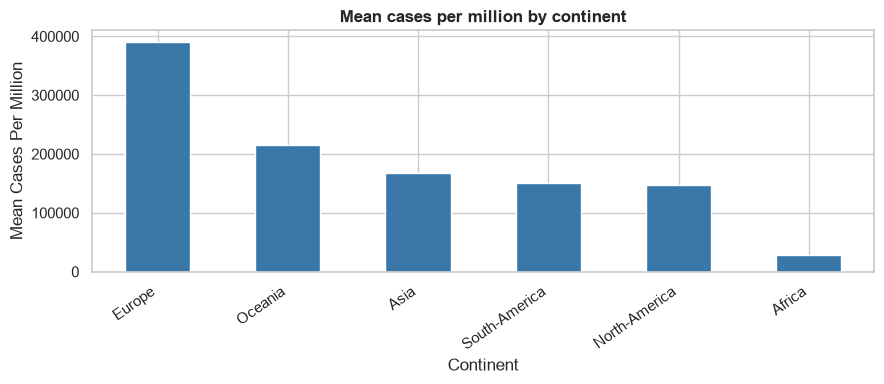

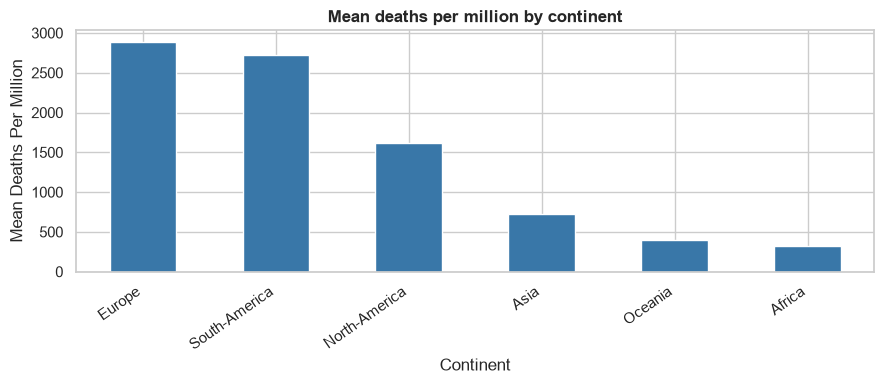

Countries without ISO-3 codes: 26


,country
7,Saint-Kitts-and-Nevis
9,Antigua-and-Barbuda
10,Sierra-Leone
11,Sao-Tome-and-Principe
18,Equatorial-Guinea
27,Saint-Lucia
30,Micronesia
32,Solomon-Islands
33,Burkina-Faso
35,South-Sudan


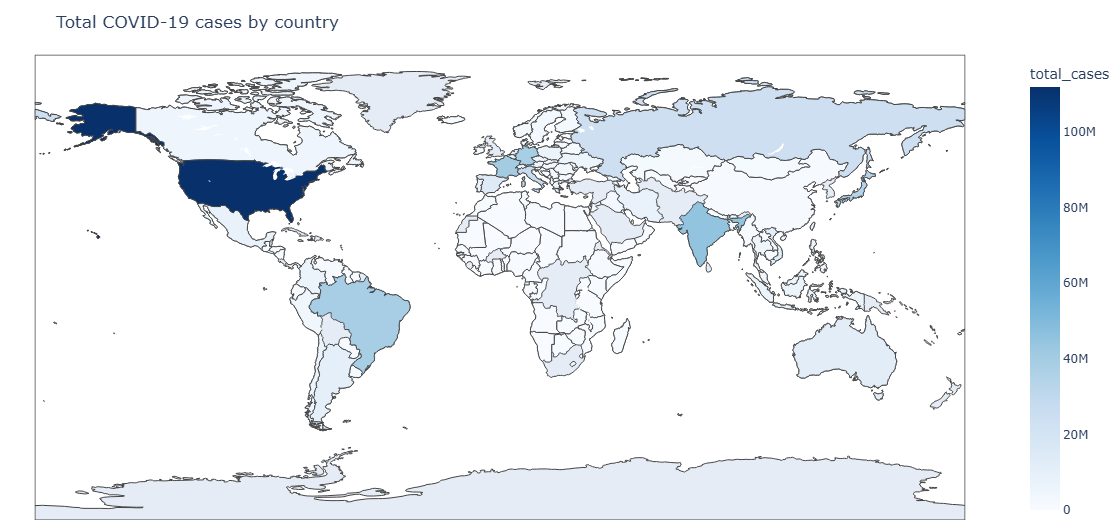

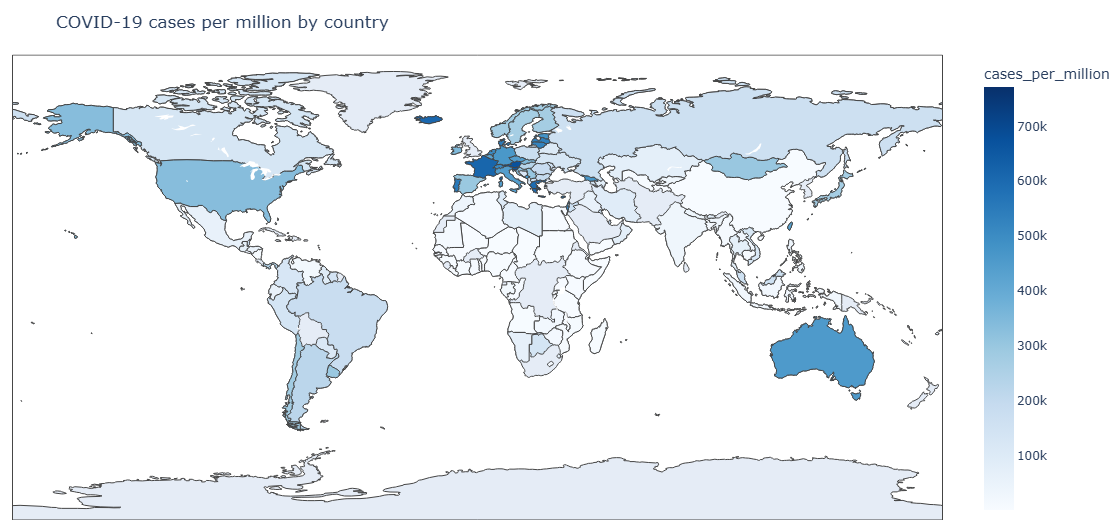

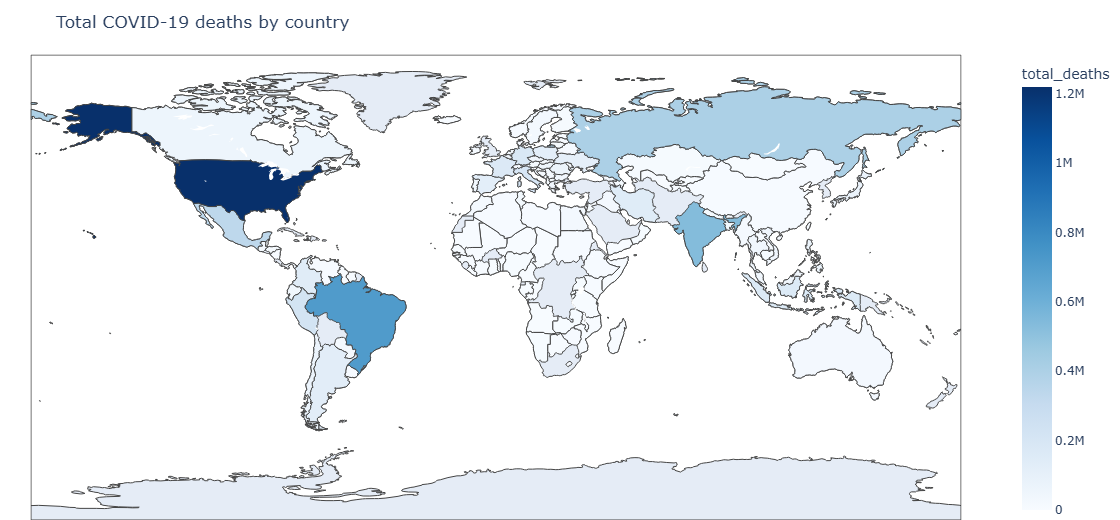

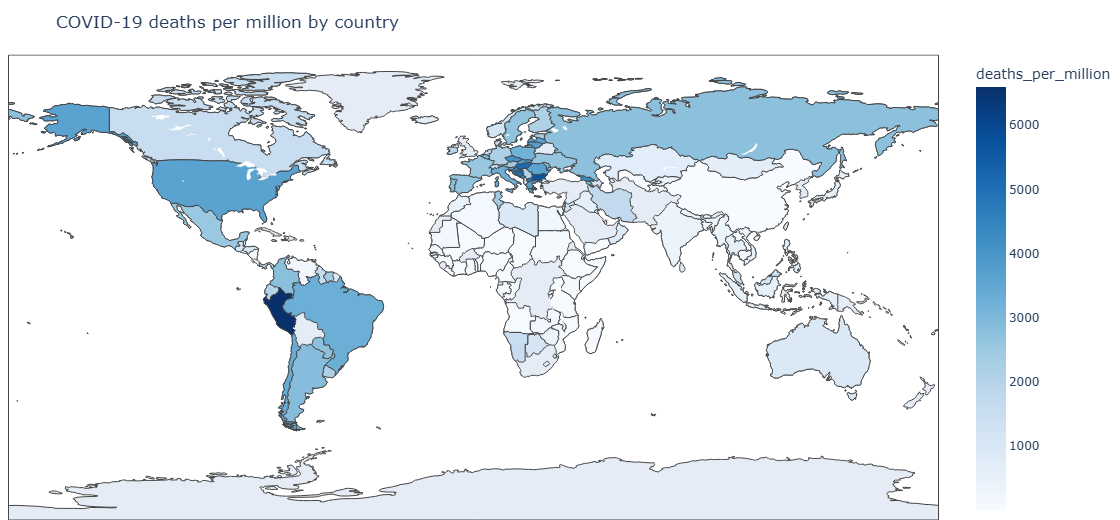

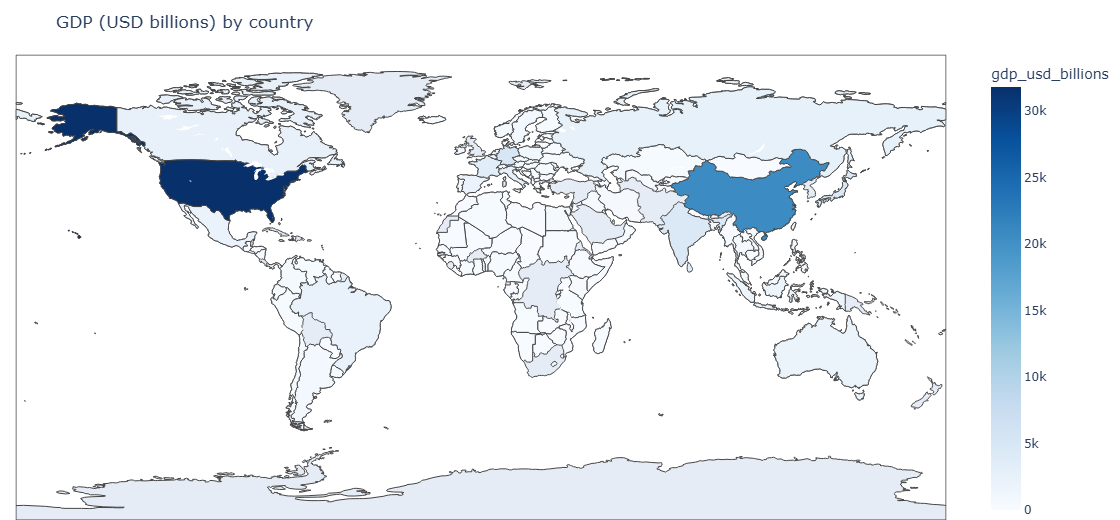

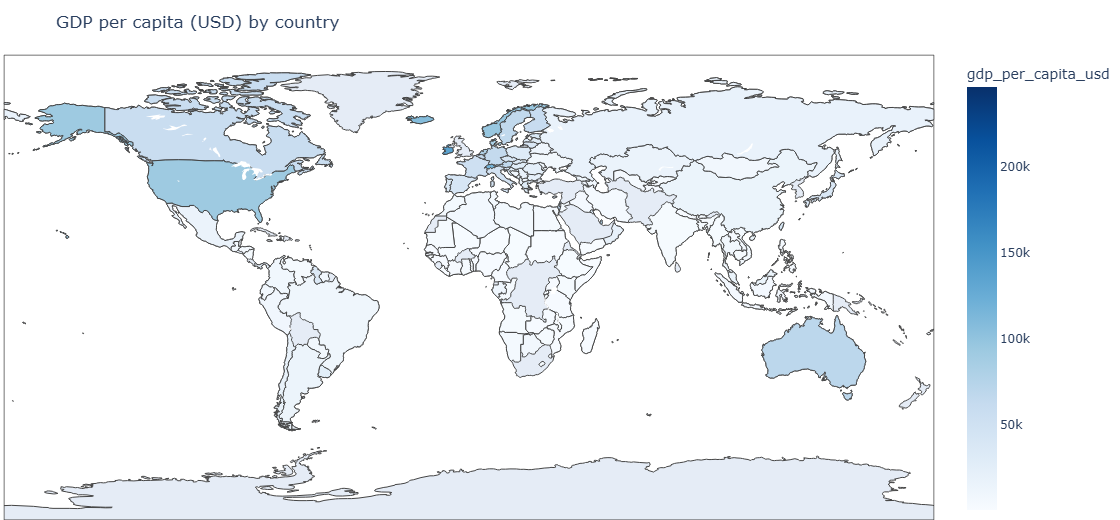

In [12]:
# Continent summary
continent_summary = df.groupby("continent", dropna=False).agg(
    countries=("country", "nunique"),
    population=("population", "sum"),
    total_cases=("total_cases", "sum"),
    total_deaths=("total_deaths", "sum"),
    mean_cases_per_million=("cases_per_million", "mean"),
    mean_deaths_per_million=("deaths_per_million", "mean"),
    mean_gdp_per_capita=("gdp_per_capita_usd", "mean")
).sort_values("total_cases", ascending=False)

display(continent_summary)


# Bar charts by continent
for col, title in [
    ("total_cases", "Total cases by continent"),
    ("total_deaths", "Total deaths by continent"),
    ("mean_cases_per_million", "Mean cases per million by continent"),
    ("mean_deaths_per_million", "Mean deaths per million by continent")
]:
    ax = continent_summary[col].sort_values(ascending=False).plot(
        kind="bar", figsize=(9, 4), color="#3977A8", title=title
    )
    ax.set_xlabel("Continent")
    ax.set_ylabel(col.replace("_", " ").title())
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


# Interactive choropleth maps
try:
    import plotly.express as px
    import pycountry

    # Handle country-name variations in the dataset
    country_aliases = {
        "USA": "United States",
        "Russia": "Russian Federation",
        "South-Korea": "Korea, Republic of",
        "North-Macedonia": "North Macedonia",
        "San-Marino": "San Marino",
        "Bosnia-and-Herzegovina": "Bosnia and Herzegovina",
        "Czech-Republic": "Czechia",
        "Ivory-Coast": "Côte d'Ivoire",
        "DR-Congo": "Congo, The Democratic Republic of the",
        "Syria": "Syrian Arab Republic",
        "Iran": "Iran, Islamic Republic of",
        "Tanzania": "Tanzania, United Republic of",
        "Venezuela": "Venezuela, Bolivarian Republic of",
        "Bolivia": "Bolivia, Plurinational State of",
        "Moldova": "Moldova, Republic of",
        "Laos": "Lao People's Democratic Republic",
        "Brunei": "Brunei Darussalam",
        "Vietnam": "Viet Nam",
        "Taiwan": "Taiwan, Province of China",
        "Palestine": "Palestine, State of"
    }

    # Convert country names into ISO-3 codes
    def get_iso3(country):
        country = country_aliases.get(country, country)

        try:
            return pycountry.countries.lookup(country).alpha_3
        except LookupError:
            return None

    df["iso3"] = df["country"].apply(get_iso3)

    # Display countries that could not be matched
    unmatched = df.loc[df["iso3"].isna(), ["country"]]

    print("Countries without ISO-3 codes:", len(unmatched))

    if not unmatched.empty:
        display(unmatched)

    # Generate interactive choropleth maps
    for col, title in [
        ("total_cases", "Total COVID-19 cases by country"),
        ("cases_per_million", "COVID-19 cases per million by country"),
        ("total_deaths", "Total COVID-19 deaths by country"),
        ("deaths_per_million", "COVID-19 deaths per million by country"),
        ("gdp_usd_billions", "GDP (USD billions) by country"),
        ("gdp_per_capita_usd", "GDP per capita (USD) by country")
    ]:
        map_df = df.dropna(subset=["iso3", col])

        fig = px.choropleth(
            map_df,
            locations="iso3",
            locationmode="ISO-3",
            color=col,
            hover_name="country",
            hover_data={
                "continent": True,
                col: ":,.2f"
            },
            color_continuous_scale="Blues",
            title=title
        )

        fig.update_layout(
            height=520,
            margin=dict(l=0, r=0, t=55, b=0)
        )

        fig.show()

except ImportError as e:
    print(
        "Interactive maps could not be rendered because "
        "a required library is not installed:", repr(e)
    )

except Exception as e:
    print(
        "Interactive maps could not be rendered in this environment:",
        repr(e)
    )



### Interpretation of Continent Summary and Global Maps

Asia recorded the highest total cases (4.31 billion), while Europe recorded the highest total deaths (253.19 million). Europe also had the highest mean cases and deaths per million, whereas Africa recorded the lowest averages for both indicators. Regarding economic indicators, Europe had the highest mean GDP per capita (USD 53,137.12), while Africa had the lowest (USD 3,284.40).

The choropleth maps illustrate geographical differences in COVID-19 outcomes across countries. Continent totals reflect differences in population and country representation, while mean rates give equal weight to each country. Uncoloured countries indicate unavailable or unmatched values, not zero cases or deaths.


## C. Inferential analysis
### Correlation analysis
Pearson correlation measures the strength and direction of a linear association between two numeric variables. The analysis reports both the correlation coefficient and its p-value. Pairwise complete observations are used.Since many correlations are tested simultaneously, the Benjamini–Hochberg false-discovery-rate adjustment is also reported; this helps reduce false positives from multiple testing. 

,population,cases_per_million,total_cases,deaths_per_million,total_deaths,gdp_usd_billions,gdp_per_capita_usd
population,1.000,-0.123,0.368,-0.075,0.399,0.576,-0.055
cases_per_million,-0.123,1.000,0.199,0.523,0.070,0.075,0.666
total_cases,0.368,0.199,1.000,0.243,0.904,0.765,0.217
deaths_per_million,-0.075,0.523,0.243,1.000,0.298,0.115,0.302
total_deaths,0.399,0.070,0.904,0.298,1.000,0.709,0.116
gdp_usd_billions,0.576,0.075,0.765,0.115,0.709,1.000,0.190
gdp_per_capita_usd,-0.055,0.666,0.217,0.302,0.116,0.190,1.000


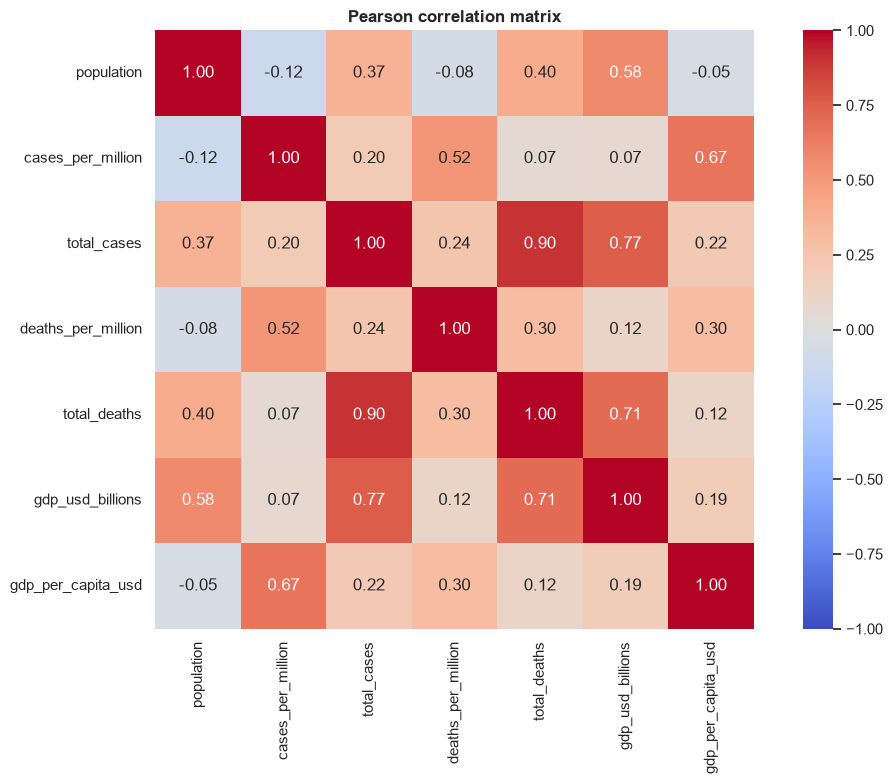

,Variable 1,Variable 2,N,Pearson r,p-value,p-value (BH adjusted),Significant at 5% (adjusted)
12,total_cases,total_deaths,184,0.904,0.000,0.000,True
13,total_cases,gdp_usd_billions,184,0.765,0.000,0.000,True
18,total_deaths,gdp_usd_billions,184,0.709,0.000,0.000,True
10,cases_per_million,gdp_per_capita_usd,184,0.666,0.000,0.000,True
4,population,gdp_usd_billions,184,0.576,0.000,0.000,True
7,cases_per_million,deaths_per_million,184,0.523,0.000,0.000,True
3,population,total_deaths,184,0.399,0.000,0.000,True
1,population,total_cases,184,0.368,0.000,0.000,True
17,deaths_per_million,gdp_per_capita_usd,184,0.302,0.000,0.000,True
15,deaths_per_million,total_deaths,184,0.298,0.000,0.000,True


In [13]:
corr_cols = numeric_cols
corr_matrix = df[corr_cols].corr(method="pearson")
display(corr_matrix)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Pearson correlation matrix")
plt.tight_layout()
plt.show()

corr_results = []
for i, x in enumerate(corr_cols):
    for y in corr_cols[i+1:]:
        pair = df[[x, y]].dropna()
        if len(pair) >= 3 and pair[x].nunique() > 1 and pair[y].nunique() > 1:
            r, pval = stats.pearsonr(pair[x], pair[y])
            corr_results.append([x, y, len(pair), r, pval])
corr_table = pd.DataFrame(corr_results, columns=["Variable 1", "Variable 2", "N", "Pearson r", "p-value"])
if not corr_table.empty:
    corr_table["p-value (BH adjusted)"] = multipletests(corr_table["p-value"], method="fdr_bh")[1]
    corr_table["Significant at 5% (adjusted)"] = corr_table["p-value (BH adjusted)"] < .05
    corr_table = corr_table.sort_values("p-value (BH adjusted)")
display(corr_table)

**Correlation Interpretation:** Positive correlation indicates that two variables tend to increase together, while negative correlation indicates an inverse relationship. Coefficients closer to +1 or −1 represent stronger linear associations, whereas values near zero indicate weaker associations. Statistical significance is determined using the Benjamini–Hochberg (BH)-adjusted p-values at the 5% level. However, statistical significance does not necessarily imply practical importance, and correlation does not establish causation.

## Simple linear regression and diagnostic plots
Eight separate ordinary least squares (OLS) models are fitted. For each model, the notebook reports the sample size, intercept, slope, R-squared, adjusted R-squared, RMSE, slope p-value, and 95% confidence interval. The residuals-versus-fitted plot is inspected for curvature, changing spread, and unusual observations. The Normal Q-Q plot is inspected for departures from normality, especially in the tails.

\n=====================================================================================
Total cases vs population
                            OLS Regression Results                            
Dep. Variable:            total_cases   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     28.51
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           2.76e-07
Time:                        12:51:29   Log-Likelihood:                -3228.5
No. Observations:                 184   AIC:                             6461.
Df Residuals:                     182   BIC:                             6467.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------

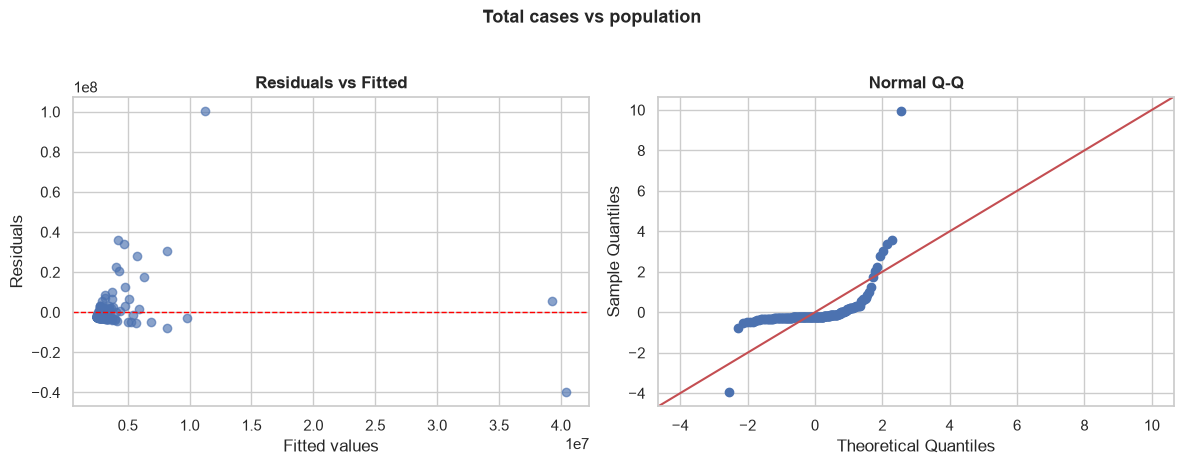

Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;
a funnel/fan shape suggests non-constant variance; isolated points may be influential.
Normal Q-Q comment: Points close to the reference line support approximate normality;
systematic curvature or tail departures indicate non-normal residuals.
\n=====================================================================================
Total deaths vs population
                            OLS Regression Results                            
Dep. Variable:           total_deaths   R-squared:                       0.159
Model:                            OLS   Adj. R-squared:                  0.155
Method:                 Least Squares   F-statistic:                     34.47
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           2.02e-08
Time:                        12:51:30   Log-Likelihood:                -2398.7
No. Observations:                 184   AIC:                             48

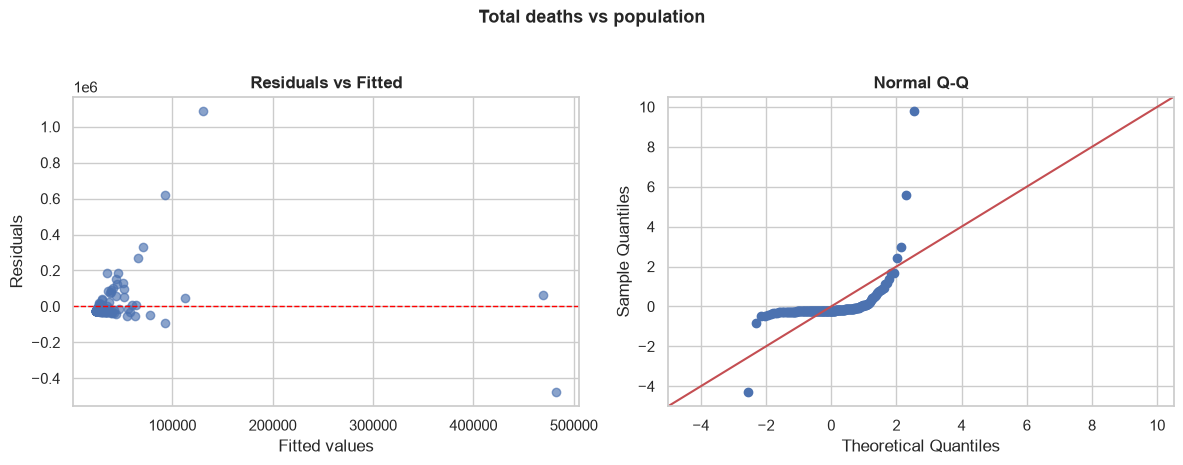

Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;
a funnel/fan shape suggests non-constant variance; isolated points may be influential.
Normal Q-Q comment: Points close to the reference line support approximate normality;
systematic curvature or tail departures indicate non-normal residuals.
\n=====================================================================================
Total cases vs GDP
                            OLS Regression Results                            
Dep. Variable:            total_cases   R-squared:                       0.586
Model:                            OLS   Adj. R-squared:                  0.584
Method:                 Least Squares   F-statistic:                     257.6
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.09e-36
Time:                        12:51:30   Log-Likelihood:                -3160.8
No. Observations:                 184   AIC:                             6326.
Df R

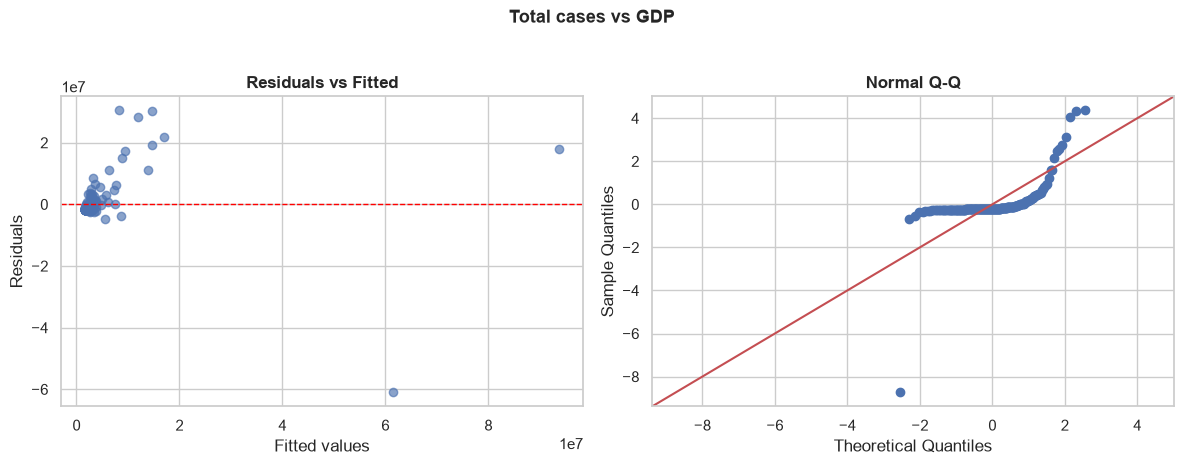

Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;
a funnel/fan shape suggests non-constant variance; isolated points may be influential.
Normal Q-Q comment: Points close to the reference line support approximate normality;
systematic curvature or tail departures indicate non-normal residuals.
\n=====================================================================================
Total cases vs GDP per capita
                            OLS Regression Results                            
Dep. Variable:            total_cases   R-squared:                       0.047
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     8.982
Date:                Sun, 01 Nov 2026   Prob (F-statistic):            0.00311
Time:                        12:51:31   Log-Likelihood:                -3237.5
No. Observations:                 184   AIC:                            

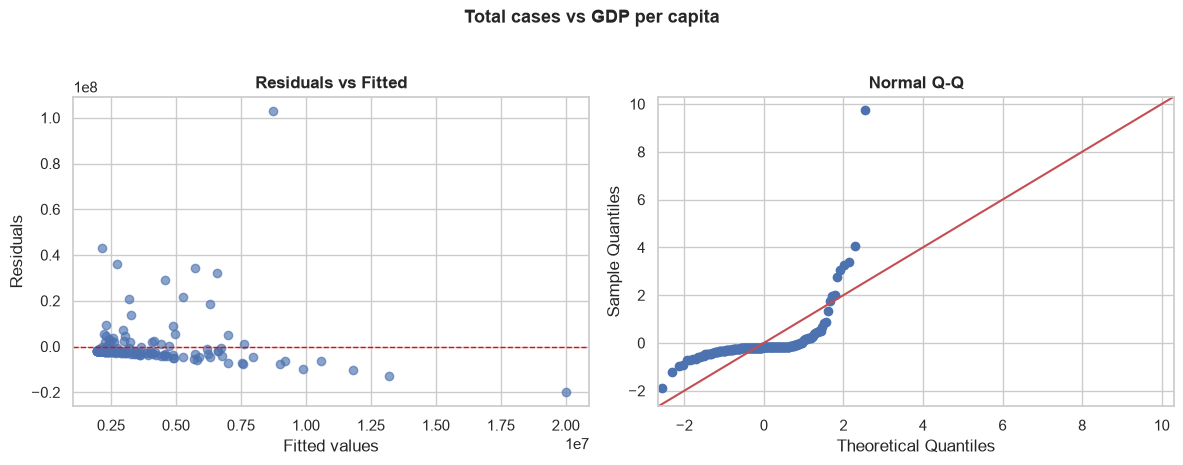

Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;
a funnel/fan shape suggests non-constant variance; isolated points may be influential.
Normal Q-Q comment: Points close to the reference line support approximate normality;
systematic curvature or tail departures indicate non-normal residuals.
\n=====================================================================================
Cases per million vs GDP
                            OLS Regression Results                            
Dep. Variable:      cases_per_million   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.027
Date:                Sun, 01 Nov 2026   Prob (F-statistic):              0.312
Time:                        12:51:31   Log-Likelihood:                -2503.4
No. Observations:                 184   AIC:                             5011

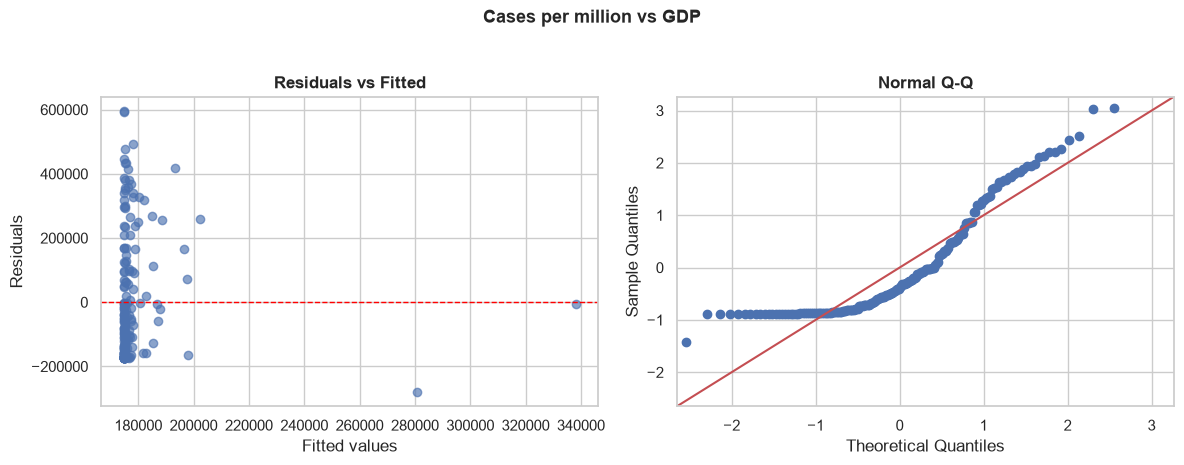

Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;
a funnel/fan shape suggests non-constant variance; isolated points may be influential.
Normal Q-Q comment: Points close to the reference line support approximate normality;
systematic curvature or tail departures indicate non-normal residuals.
\n=====================================================================================
Cases per million vs GDP per capita
                            OLS Regression Results                            
Dep. Variable:      cases_per_million   R-squared:                       0.443
Model:                            OLS   Adj. R-squared:                  0.440
Method:                 Least Squares   F-statistic:                     144.9
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           6.32e-25
Time:                        12:51:31   Log-Likelihood:                -2450.0
No. Observations:                 184   AIC:                      

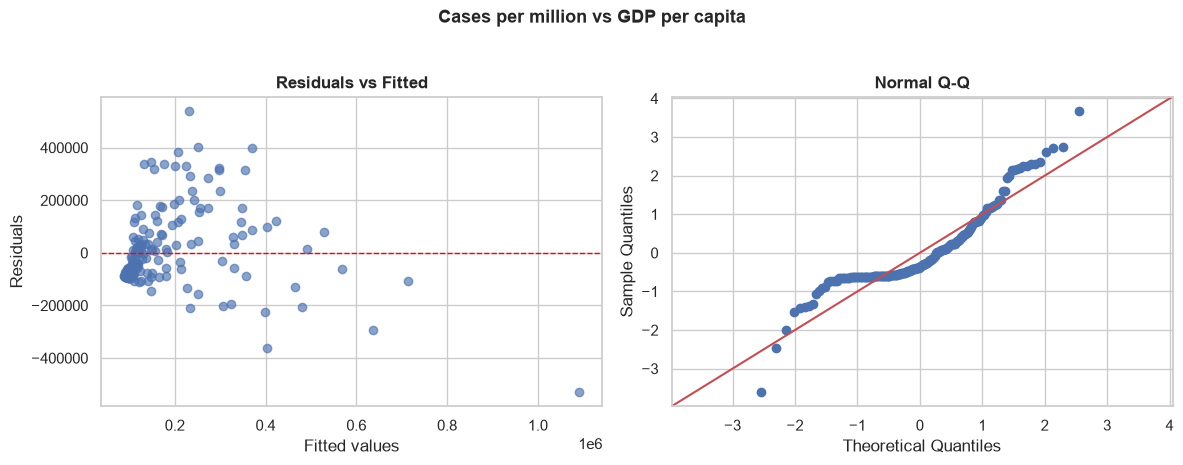

Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;
a funnel/fan shape suggests non-constant variance; isolated points may be influential.
Normal Q-Q comment: Points close to the reference line support approximate normality;
systematic curvature or tail departures indicate non-normal residuals.
\n=====================================================================================
Total deaths vs GDP per capita
                            OLS Regression Results                            
Dep. Variable:           total_deaths   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     2.494
Date:                Sun, 01 Nov 2026   Prob (F-statistic):              0.116
Time:                        12:51:32   Log-Likelihood:                -2413.4
No. Observations:                 184   AIC:                           

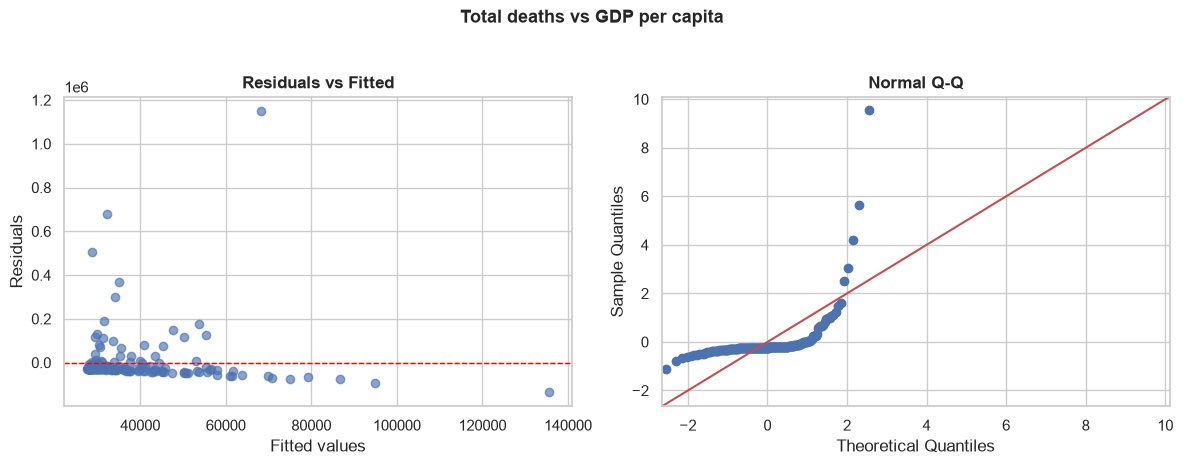

Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;
a funnel/fan shape suggests non-constant variance; isolated points may be influential.
Normal Q-Q comment: Points close to the reference line support approximate normality;
systematic curvature or tail departures indicate non-normal residuals.
\n=====================================================================================
Deaths per million vs GDP per capita
                            OLS Regression Results                            
Dep. Variable:     deaths_per_million   R-squared:                       0.091
Model:                            OLS   Adj. R-squared:                  0.086
Method:                 Least Squares   F-statistic:                     18.21
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           3.18e-05
Time:                        12:51:32   Log-Likelihood:                -1583.4
No. Observations:                 184   AIC:                     

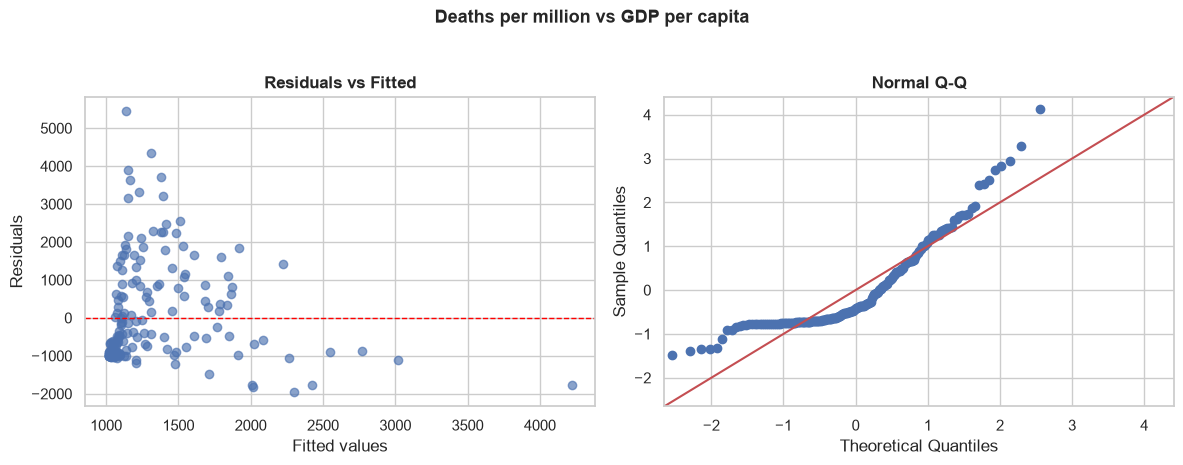

Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;
a funnel/fan shape suggests non-constant variance; isolated points may be influential.
Normal Q-Q comment: Points close to the reference line support approximate normality;
systematic curvature or tail departures indicate non-normal residuals.


,Model,N,Intercept,Slope,R-squared,Adjusted R-squared,RMSE,Slope p-value,Slope 95% CI lower,Slope 95% CI upper
0,Total cases vs population,184,"2,503,013.216",0.026,0.135,0.131,"10,092,096.754",0.000,0.016,0.036
1,Total deaths vs population,184,"24,379.171",0.000,0.159,0.155,"111,028.232",0.000,0.000,0.000
2,Total cases vs GDP,184,"1,670,893.022","2,894.294",0.586,0.584,"6,984,010.310",0.000,"2,538.460","3,250.128"
3,Total cases vs GDP per capita,184,"1,930,650.582",73.209,0.047,0.042,"10,595,433.041",0.003,25.011,121.407
4,Cases per million vs GDP,184,"174,834.572",5.131,0.006,0.000,"196,105.724",0.312,-4.860,15.123
5,Cases per million vs GDP per capita,184,"86,971.780",4.072,0.443,0.440,"146,738.584",0.000,3.405,4.740
6,Total deaths vs GDP per capita,184,"27,485.007",0.438,0.014,0.008,"120,264.214",0.116,-0.109,0.985
7,Deaths per million vs GDP per capita,184,"1,012.217",0.013,0.091,0.086,"1,321.661",0.000,0.007,0.019


In [14]:
regression_pairs = [
    ("total_cases", "population", "Total cases vs population"),
    ("total_deaths", "population", "Total deaths vs population"),
    ("total_cases", "gdp_usd_billions", "Total cases vs GDP"),
    ("total_cases", "gdp_per_capita_usd", "Total cases vs GDP per capita"),
    ("cases_per_million", "gdp_usd_billions", "Cases per million vs GDP"),
    ("cases_per_million", "gdp_per_capita_usd", "Cases per million vs GDP per capita"),
    ("total_deaths", "gdp_per_capita_usd", "Total deaths vs GDP per capita"),
    ("deaths_per_million", "gdp_per_capita_usd", "Deaths per million vs GDP per capita")
]

regression_results = []
regression_models = {}

for y, x, label in regression_pairs:
    dat = df[[x, y]].dropna()
    if len(dat) < 4 or dat[x].nunique() < 2:
        print(f"Skipped {label}: insufficient usable observations or predictor variation.")
        continue

    X = sm.add_constant(dat[x])
    model = sm.OLS(dat[y], X).fit()
    regression_models[label] = (model, dat, x, y)

    pred = model.predict(X)
    residuals = model.resid
    rmse = float(np.sqrt(np.mean(residuals**2)))
    slope = model.params[x]
    ci_low, ci_high = model.conf_int().loc[x].tolist()
    regression_results.append({
        "Model": label, "N": int(model.nobs), "Intercept": model.params["const"],
        "Slope": slope, "R-squared": model.rsquared,
        "Adjusted R-squared": model.rsquared_adj, "RMSE": rmse,
        "Slope p-value": model.pvalues[x],
        "Slope 95% CI lower": ci_low, "Slope 95% CI upper": ci_high
    })

    print("\\n" + "="*85)
    print(label)
    print(model.summary())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].scatter(pred, residuals, alpha=.65)
    axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
    axes[0].set_title("Residuals vs Fitted")
    axes[0].set_xlabel("Fitted values")
    axes[0].set_ylabel("Residuals")

    sm.qqplot(residuals, line="45", ax=axes[1], fit=True)
    axes[1].set_title("Normal Q-Q")
    plt.suptitle(label, y=1.03, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print("Residual plot comment: Look for random scatter around zero. A curve suggests non-linearity;")
    print("a funnel/fan shape suggests non-constant variance; isolated points may be influential.")
    print("Normal Q-Q comment: Points close to the reference line support approximate normality;")
    print("systematic curvature or tail departures indicate non-normal residuals.")

regression_table = pd.DataFrame(regression_results)
display(regression_table)

### Regression Significance and Interpretation

The slope p-value tests whether the predictor has a statistically significant linear association with the response. A p-value below 0.05 indicates significance at the 5% level. The 95% confidence interval shows the plausible range of the population slope.

R-squared measures the proportion of variation in the response explained by the predictor. However, statistical significance does not necessarily imply strong explanatory power or causation. Slope coefficients are interpreted in the units of the variables, and model adequacy assessed using the residual and Normal Q-Q plots.

## Summary of regression findings

In [15]:
if not regression_table.empty:
    summary = regression_table.copy()
    summary["Significant at 5%"] = summary["Slope p-value"] < .05
    summary["R-squared"] = summary["R-squared"].round(4)
    summary["Slope p-value"] = summary["Slope p-value"].apply(lambda p: f"{p:.3g}")
    display(summary[["Model", "N", "Slope", "R-squared", "Slope p-value", "Significant at 5%"]])
    best = regression_table.loc[regression_table["R-squared"].idxmax()]
    print(f"Highest in-sample R-squared among the eight specified models: {best['Model']} "
          f"(R-squared = {best['R-squared']:.4f}, N = {int(best['N'])}).")

,Model,N,Slope,R-squared,Slope p-value,Significant at 5%
0,Total cases vs population,184,0.026,0.135,2.76e-07,True
1,Total deaths vs population,184,0.000,0.159,2.02e-08,True
2,Total cases vs GDP,184,"2,894.294",0.586,1.09e-36,True
3,Total cases vs GDP per capita,184,73.209,0.047,0.00311,True
4,Cases per million vs GDP,184,5.131,0.006,0.312,False
5,Cases per million vs GDP per capita,184,4.072,0.443,6.32e-25,True
6,Total deaths vs GDP per capita,184,0.438,0.013,0.116,False
7,Deaths per million vs GDP per capita,184,0.013,0.091,3.18e-05,True


Highest in-sample R-squared among the eight specified models: Total cases vs GDP (R-squared = 0.5860, N = 184).


## Conclusion

This analysis examined country-level COVID-19 and economic indicators through descriptive statistics, visualisations, Pearson correlation and eight OLS regression models. The findings highlight substantial differences in reported COVID-19 outcomes across countries and continents. Total cases and deaths reflect both population size and disease burden, while per-million rates provide a more comparable measure across countries.

The correlation and regression analyses identified linear associations between the variables, with statistical significance assessed alongside explanatory power. The regression diagnostic plots provided additional insight into the suitability of the OLS models. Any evidence of skewness, heteroscedasticity, outliers or non-normal residuals is considered when interpreting the regression results.

**Limitations:** The cross-sectional nature of the dataset prevents analysis of changes over time and does not support causal conclusions. Differences in testing, reporting, population characteristics and healthcare systems may also influence country comparisons. Furthermore, the analysis is restricted to the variables available in the dataset. Therefore, the findings are interpreted as descriptive patterns and statistical associations rather than evidence of causal relationships.